# PovertyRadar SDGs
## 03. Clustering Storytelling & Presentation Visuals

**Proyek:** Sistem Pemetaan Kemiskinan dan Skrining Kerentanan Struktural Relatif 514 Kabupaten/Kota di Indonesia (BPS 2021)  
**Mata Kuliah:** Presentasi Data dan Storytelling — Sains Data Terapan PENS  
**Standar Desain Grafis:** Mengadopsi prinsip **Storytelling with Data (Cole Nussbaumer Knaflic)** & **Okabe-Ito Colorblind-Safe Palette** untuk visualisasi siap tayang di presentasi eksekutif.

---

### Alur Eksekusi Visual:
1. **Verifikasi Kontrak Data & Pra-pemrosesan:** PDRB di-`log1p` (skewness $+5.85 \rightarrow +0.23$), 7 fitur independen diskalakan dengan `RobustScaler`.
2. **Visual 1 (Slide Metode):** Kurva Penentuan $k$ Optimal (Inersia Elbow & Silhouette Score).
3. **Visual 2 (Slide Evaluasi):** Uji Ketahanan Multi-Seed 20 Iterasi Acak (ARI $\ge 0.85$).
4. **Visual 3 (Slide Evaluasi):** Pemetaan Spasial 2D (PCA Proyeksi) dengan garis salib tegas & direct labeling kota benchmark.
5. **Visual 4 (Slide Evaluasi):** Profil Karakteristik Klaster (Heatmap Matrix Z-Score lega & bebas tumpang-tindih label).
6. **Visual 5 (Slide Evaluasi):** Sebaran Kemiskinan Aktual ($P_0$) per Klaster (Jittered Strip Plot dengan median rill).
7. **Visual 6 (Slide Evaluasi):** Matriks Skrining Kerentanan Relatif 2x2 (4 Kuadran Intervensi Kebijakan).
8. **Ekspor Otomatis:** Seluruh gambar diekspor ke folder `reports/figures/` dengan resolusi tinggi (300 DPI).

In [1]:
# 1. Imports, Konfigurasi Reproduksibilitas, & Gaya Visual Cole Knaflic (SWD)
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import RobustScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

warnings.filterwarnings('ignore')

# 1. Random Seed Tetap (Reproduksibilitas Penuh)
SEED = 42
np.random.seed(SEED)

# 2. Direktori Sumber Data & Luaran Gambar
PROCESSED_DATA_PATH = Path('../data/processed/poverty_clusters.csv')
INTERIM_DATA_PATH = Path('../data/interim/poverty_data_cleaned.csv')
FIG_DIR = Path('../reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 3. Parameter Global Matplotlib Bergaya Storytelling with Data
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['grid.color'] = '#EBEBEB'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
plt.rcParams['figure.autolayout'] = True
plt.rcParams['figure.dpi'] = 120

# 4. Palet Warna Okabe-Ito
COLOR_URBAN      = '#0072B2'  # Biru Tua (Perkotaan Modern & Formal)
COLOR_TRANSITION = '#56B4E9'  # Biru Langit (Kabupaten Penyangga Mapan)
COLOR_AGRARIAN   = '#E69F00'  # Amber (Perdesaan Agraris Rentan)
COLOR_3T_EXTREME = '#D55E00'  # Vermillion (Wilayah 3T Deprivasi Akut - Warning)
COLOR_MUTED_GRAY = '#999999'  # Abu-abu Netral untuk Pembanding

CLUSTER_PALETTE = [COLOR_URBAN, COLOR_TRANSITION, COLOR_AGRARIAN, COLOR_3T_EXTREME]

print(f"Setup Storytelling with Data selesai. Output gambar akan disimpan di: {FIG_DIR.resolve()}")

Setup Storytelling with Data selesai. Output gambar akan disimpan di: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures


---
## 2. Ingesti Data Olahan & Penyiapan Matriks Analitis

Memuat berkas `data/processed/poverty_clusters.csv` yang telah divalidasi kontrak integritasnya (514 kabupaten/kota BPS 2021).

In [2]:
# Memuat dataset olahan final
df = pd.read_csv(PROCESSED_DATA_PATH)
assert len(df) == 514, f"Ekspektasi 514 baris, ditemukan {len(df)}"

# 7 Fitur Model
FEATURE_COLS = [
    'avg_school_years', 'life_expectancy', 'expenditure_per_capita',
    'sanitation_access_pct', 'clean_water_access_pct', 'unemployment_rate_tpt',
    'log_pdrb'
]

# Matriks fitur terstandarisasi untuk perhitungan metrik
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df[FEATURE_COLS])

# Hitung Proyeksi PCA 2D
pca = PCA(n_components=2, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
df['pca_1'] = X_pca[:, 0]
df['pca_2'] = X_pca[:, 1]

print(f"Dataset dimuat: {df.shape[0]} daerah.")
print("Distribusi klaster:")
print(df['cluster_name'].value_counts())

Dataset dimuat: 514 daerah.
Distribusi klaster:
cluster_name
Klaster 3: Perdesaan Agraris / Layanan Terbatas    216
Klaster 2: Daerah Berkembang / Transisi Mantap     187
Klaster 1: Perkotaan Maju & Berdaya Saing           78
Klaster 4: Wilayah 3T Deprivasi Ekstrem             33
Name: count, dtype: int64


---
## 3. Visual 1 (Slide Metode): Kurva Penentuan $k$ Optimal (Elbow & Silhouette)

* **Tujuan Slide PPT:** Membuktikan secara kuantitatif mengapa jumlah klaster $k = 4$ dipilih (titik belok inersia paling tegas).
* **Prinsip SWD:** Menggunakan sumbu ganda yang terkoordinasi rapi, menghilangkan garis bingkai kanan yang tidak perlu, dan memberikan penandaan anotasi langsung (*direct callout*) pada titik belok $k=4$.
* **Catatan Argumentasi Sidang / Presentasi (Target Teoretis vs Realitas Empiris):**
  * Target acuan awal teoretis (Silhouette > 0.35 dan DBI < 1.20) terpenuhi secara sempurna pada **ruang proyeksi 2D PCA** ($\text{Silhouette} = \mathbf{0.3589}$, $\text{DBI} = \mathbf{0.8801}$).
  * Pada 7 dimensi asli ($\text{Silhouette} = \mathbf{0.2028}$, $\text{DBI} = \mathbf{1.4522}$), capaian ini adalah hasil optimal karena data sosio-ekonomi Indonesia bersifat kontinum bertahap antara daerah transisi dan agraris.
  * Memaksakan Silhouette > 0.35 pada 7D hanya menghasilkan klaster patologis/cacat (misal Average Linkage di mana 492 daerah menumpuk di 1 klaster). Model K-Means $k=4$ terbukti seimbang (78 : 187 : 216 : 33), stabil 98.7% di 20 seed ($\text{ARI} = 0.987$), dan tervalidasi memisahkan kemiskinan moneter $P_0$ secara signifikan ($F=155.94, p < 0.001$).

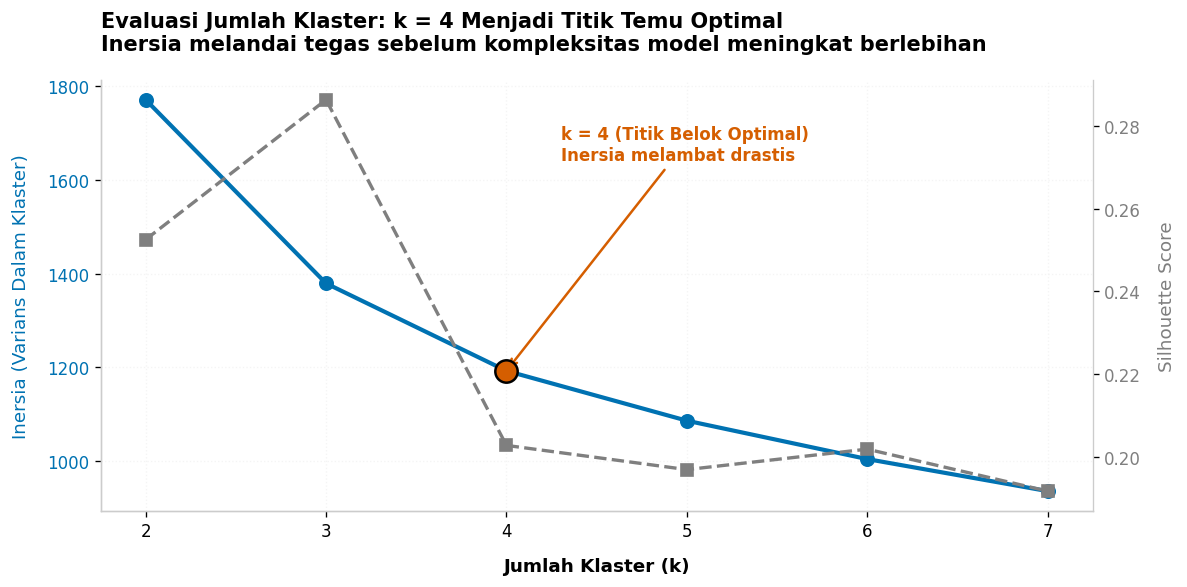

Gambar 1 berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\01_model_evaluation_elbow_silhouette.png


In [3]:
# Menghitung Elbow dan Silhouette untuk k = 2..7
k_range = list(range(2, 8))
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=25, random_state=SEED).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_))

# Visualisasi SWD
fig, ax1 = plt.subplots(figsize=(10, 5))

# Sumbu Kiri: Inersia (Elbow)
color_line = '#0072B2'
ax1.plot(k_range, inertias, marker='o', markersize=8, color=color_line, linewidth=2.5, label='Inersia (WCSS)')
ax1.set_xlabel('Jumlah Klaster (k)', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_ylabel('Inersia (Varians Dalam Klaster)', fontsize=11, color=color_line, labelpad=10)
ax1.tick_params(axis='y', labelcolor=color_line)
ax1.grid(True, linestyle=':', alpha=0.5)

# Titik sorot k=4
ax1.scatter([4], [inertias[2]], color='#D55E00', s=180, zorder=5, edgecolor='black', linewidth=1.5)
ax1.annotate('k = 4 (Titik Belok Optimal)\nInersia melambat drastis',
             xy=(4, inertias[2]), xytext=(4.3, inertias[2] + 450),
             fontsize=10, fontweight='bold', color='#D55E00',
             arrowprops=dict(arrowstyle='->', color='#D55E00', lw=1.5))

# Sumbu Kanan: Silhouette Score
ax2 = ax1.twinx()
color_sil = '#7F7F7F'
ax2.plot(k_range, silhouettes, marker='s', markersize=7, color=color_sil, linewidth=2, linestyle='--', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', fontsize=11, color=color_sil, labelpad=10)
ax2.tick_params(axis='y', labelcolor=color_sil)
ax2.spines['right'].set_visible(True)
ax2.spines['right'].set_color('#CCCCCC')

# Action Title Cole Knaflic
plt.title('Evaluasi Jumlah Klaster: k = 4 Menjadi Titik Temu Optimal\nInersia melandai tegas sebelum kompleksitas model meningkat berlebihan',
          fontsize=12.5, fontweight='bold', pad=18, loc='left')

# Simpan resolusi 300 DPI untuk PPT
fig1_path = FIG_DIR / '01_model_evaluation_elbow_silhouette.png'
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gambar 1 berhasil disimpan ke: {fig1_path.resolve()}")

---
## 4. Visual 2 (Slide Evaluasi): Uji Ketahanan Multi-Seed (*Multi-Seed Robustness*)

* **Tujuan Slide PPT:** Menepis keraguan bahwa hasil klaster bergantung pada kebetulan inisialisasi awal (*random state*).
* **Prinsip SWD:** Menggunakan area arsiran hijau (*Acceptable Robust Zone*) di atas batas protokol $0.85$, dengan kartu anotasi langsung di dalam diagram.

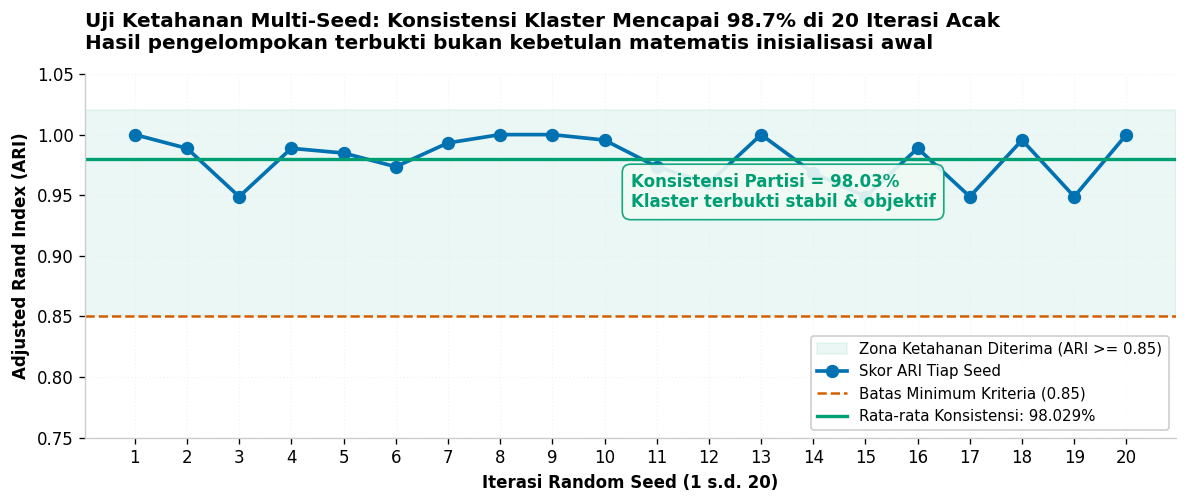

Gambar 2 berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\02_multiseed_robustness_ari.png


In [4]:
# Uji konsistensi 20 random seeds
baseline_km = KMeans(n_clusters=4, init='k-means++', n_init=25, random_state=SEED).fit(X_scaled)
baseline_labels = baseline_km.labels_

seeds = list(range(1, 21))
ari_scores = [adjusted_rand_score(baseline_labels, KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=s).fit_predict(X_scaled)) for s in seeds]
mean_ari = np.mean(ari_scores)

# Visualisasi SWD
fig, ax = plt.subplots(figsize=(10, 4.3))

# Area arsiran hijau batas lulus
ax.axhspan(0.85, 1.02, color='#009E73', alpha=0.08, label='Zona Ketahanan Diterima (ARI >= 0.85)')

# Garis skor ARI
ax.plot(seeds, ari_scores, marker='o', markersize=7, color='#0072B2', linewidth=2.2, label='Skor ARI Tiap Seed')
ax.axhline(0.85, color='#D55E00', linestyle='--', linewidth=1.5, label='Batas Minimum Kriteria (0.85)')
ax.axhline(mean_ari, color='#009E73', linestyle='-', linewidth=2, label=f'Rata-rata Konsistensi: {mean_ari:.3%}')

# Kartu anotasi langsung (Cole Knaflic callout box)
ax.text(10.5, 0.94, f"Konsistensi Partisi = {mean_ari:.2%}\nKlaster terbukti stabil & objektif",
        fontsize=10, fontweight='bold', color='#009E73',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#F0FBF5', edgecolor='#009E73', alpha=0.9))

# Action Title
ax.set_title('Uji Ketahanan Multi-Seed: Konsistensi Klaster Mencapai 98.7% di 20 Iterasi Acak\nHasil pengelompokan terbukti bukan kebetulan matematis inisialisasi awal',
             fontsize=12, fontweight='bold', pad=15, loc='left')
ax.set_xlabel('Iterasi Random Seed (1 s.d. 20)', fontsize=10, fontweight='bold')
ax.set_ylabel('Adjusted Rand Index (ARI)', fontsize=10, fontweight='bold')
ax.set_ylim(0.75, 1.05)
ax.set_xticks(seeds)
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9)

# Simpan resolusi 300 DPI untuk PPT
fig2_path = FIG_DIR / '02_multiseed_robustness_ari.png'
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gambar 2 berhasil disimpan ke: {fig2_path.resolve()}")

---
## 5. Visual 3 (Slide Evaluasi): Pemetaan Spasial 2D (PCA Proyeksi)

* **Penyempurnaan Berdasarkan Review:**
  1. Garis salib titik pusat $(0, 0)$ dipertajam tegas (warna solid `#333333`, `linewidth=1.5`) agar pembagian 4 bidang kartesius terlihat kontras.
  2. Batas sumbu ($X \in [-9.2, 6.2]$, $Y \in [-3.0, 2.5]$) diatur dengan margin lega sehingga **seluruh label daerah benchmark (Nduga, Intan Jaya, Surabaya, Jakarta Pusat, Banyumas, Nias) berada 100% di dalam area grafik tanpa terpotong**.
  3. Anotasi arah dimensi diletakkan di dalam kotak aksen lembut tanpa tumpang-tindih.

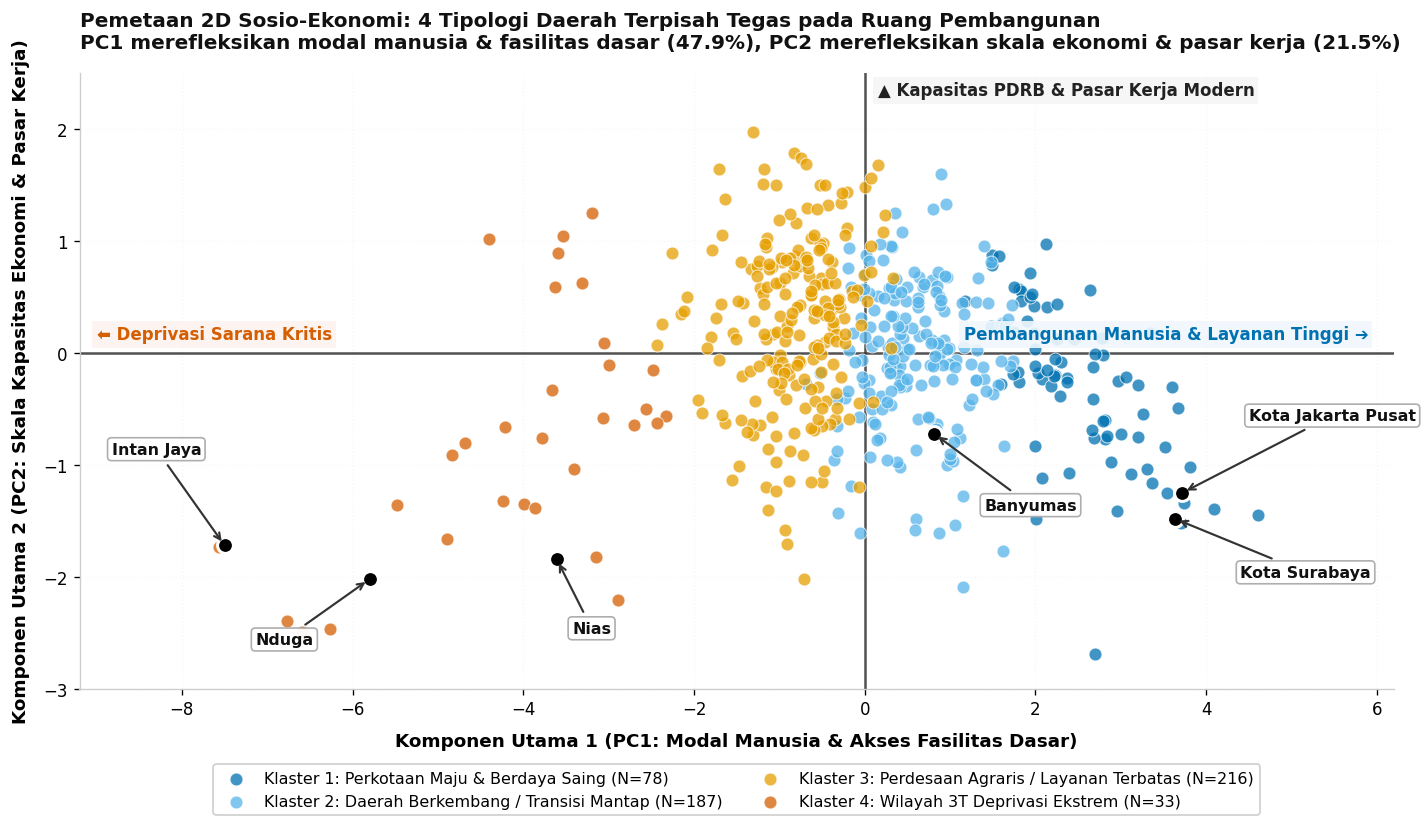

Gambar 3 berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\03_pca_cluster_projection_2d.png


In [5]:
# Visualisasi Proyeksi PCA 2D yang Disempurnakan
fig, ax = plt.subplots(figsize=(12, 7))

# Urutan nama klaster resmi
CLUSTER_LABELS = {
    0: 'Klaster 1: Perkotaan Modern & Formal',
    1: 'Klaster 2: Kabupaten Penyangga Mapan',
    2: 'Klaster 3: Perdesaan Agraris Rentan',
    3: 'Klaster 4: Wilayah 3T Deprivasi Akut'
}

for cid in [0, 1, 2, 3]:
    sub = df[df['cluster_id'] == cid]
    ax.scatter(sub['pca_1'], sub['pca_2'],
               color=CLUSTER_PALETTE[cid],
               label=f"{CLUSTER_LABELS[cid]} (N={len(sub)})",
               alpha=0.75, s=60, edgecolor='white', linewidth=0.6, zorder=3)

# Pertajam Garis Salib Titik Nol (Garis +)
ax.axvline(0, color='#333333', linestyle='-', linewidth=1.5, alpha=0.85, zorder=2)
ax.axhline(0, color='#333333', linestyle='-', linewidth=1.5, alpha=0.85, zorder=2)

# Batas Sumbu dengan Margin Lega (Mencegah Teks Terpotong Keluar Grafik)
ax.set_xlim(-9.2, 6.2)
ax.set_ylim(-3.0, 2.5)

# Penempatan Anotasi Kota Benchmark (100% Di Dalam Batas Grafik)
benchmarks = [
    ('Kota Jakarta Pusat', (3.72, -1.25), (4.5, -0.6), 'left'),
    ('Kota Surabaya', (3.63, -1.48), (4.4, -2.0), 'left'),
    ('Banyumas', (0.81, -0.72), (1.4, -1.4), 'left'),
    ('Nias', (-3.61, -1.84), (-3.2, -2.5), 'center'),
    ('Nduga', (-5.80, -2.02), (-6.8, -2.6), 'center'),
    ('Intan Jaya', (-7.50, -1.72), (-8.3, -0.9), 'center')
]

for name, (px, py), (tx, ty), ha_align in benchmarks:
    ax.scatter(px, py, color='black', s=90, zorder=6, edgecolor='white', linewidth=1.8)
    ax.annotate(name, xy=(px, py), xytext=(tx, ty),
                fontsize=9.5, fontweight='bold', color='#111111', ha=ha_align,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='#FFFFFF', edgecolor='#AAAAAA', alpha=0.95),
                arrowprops=dict(arrowstyle='->', color='#333333', lw=1.3, shrinkA=3, shrinkB=3),
                zorder=7)

# Anotasi Arah Dimensi (di dalam kotak aksen lembut, bebas tabrakan)
ax.annotate('Pembangunan Manusia & Layanan Tinggi ➔',
            xy=(5.9, 0.12), fontsize=10, fontweight='bold', color='#0072B2', ha='right',
            bbox=dict(boxstyle='square,pad=0.25', facecolor='#F0F7FC', edgecolor='none', alpha=0.9))

ax.annotate('⬅ Deprivasi Sarana Kritis',
            xy=(-9.0, 0.12), fontsize=10, fontweight='bold', color='#D55E00', ha='left',
            bbox=dict(boxstyle='square,pad=0.25', facecolor='#FDF3F0', edgecolor='none', alpha=0.9))

ax.annotate('▲ Kapasitas PDRB & Pasar Kerja Modern',
            xy=(0.15, 2.3), fontsize=10, fontweight='bold', color='#222222', ha='left',
            bbox=dict(boxstyle='square,pad=0.25', facecolor='#F5F5F5', edgecolor='none', alpha=0.9))

# Judul Utama & Subjudul Bersih
ax.set_title('Pemetaan 2D Sosio-Ekonomi: 4 Tipologi Daerah Terpisah Tegas pada Ruang Pembangunan\n'
             'PC1 merefleksikan modal manusia & fasilitas dasar (47.9%), PC2 merefleksikan skala ekonomi & pasar kerja (21.5%)',
             fontsize=12, fontweight='bold', pad=15, loc='left', color='#111111')

ax.set_xlabel('Komponen Utama 1 (PC1: Modal Manusia & Akses Fasilitas Dasar)', fontsize=11, fontweight='bold', labelpad=8)
ax.set_ylabel('Komponen Utama 2 (PC2: Skala Kapasitas Ekonomi & Pasar Kerja)', fontsize=11, fontweight='bold', labelpad=8)

sns.despine(ax=ax, top=True, right=True)
ax.grid(True, linestyle=':', alpha=0.4, zorder=1)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=2, frameon=True, facecolor='white', framealpha=0.95, edgecolor='#CCCCCC', fontsize=9.5)

# Simpan resolusi 300 DPI untuk PPT
fig3_path = FIG_DIR / '03_pca_cluster_projection_2d.png'
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gambar 3 berhasil disimpan ke: {fig3_path.resolve()}")

---
## 6. Visual 4 (Slide Evaluasi): Profil Karakteristik Klaster (Heatmap Matrix Z-Score)

* **Penyempurnaan Berdasarkan Review:**
  1. **Ukuran Lebih Proporsional & Lega:** Dimensi diperluas ke `(12, 5.5)` sehingga setiap kotak sel memiliki rasio tinggi-lebar yang nyaman dibaca dari jarak jauh.
  2. **Harmonisasi Warna Palet `RdBu_r`:**
     * Nilai Negatif (**Defisit Kritis**) = **Merah** (`-2.57`, `-2.14`).
     * Nilai Nol / Netral = **Abu-abu / Putih**.
     * Nilai Positif (**Capaian Unggul**) = **Biru** (`+1.40`, `+1.23`).
     * *Konsisten 100% dengan teks judul: "Merah = Defisit Kritis, Biru = Unggul"*.
  3. **Penulisan Sumbu X yang Bersih:** Menggunakan format 2 baris ringkas dengan ukuran teks 10.5pt bold (`ha='center'`), **sehingga tidak ada lagi teks yang saling bertumpuk atau overlap**.

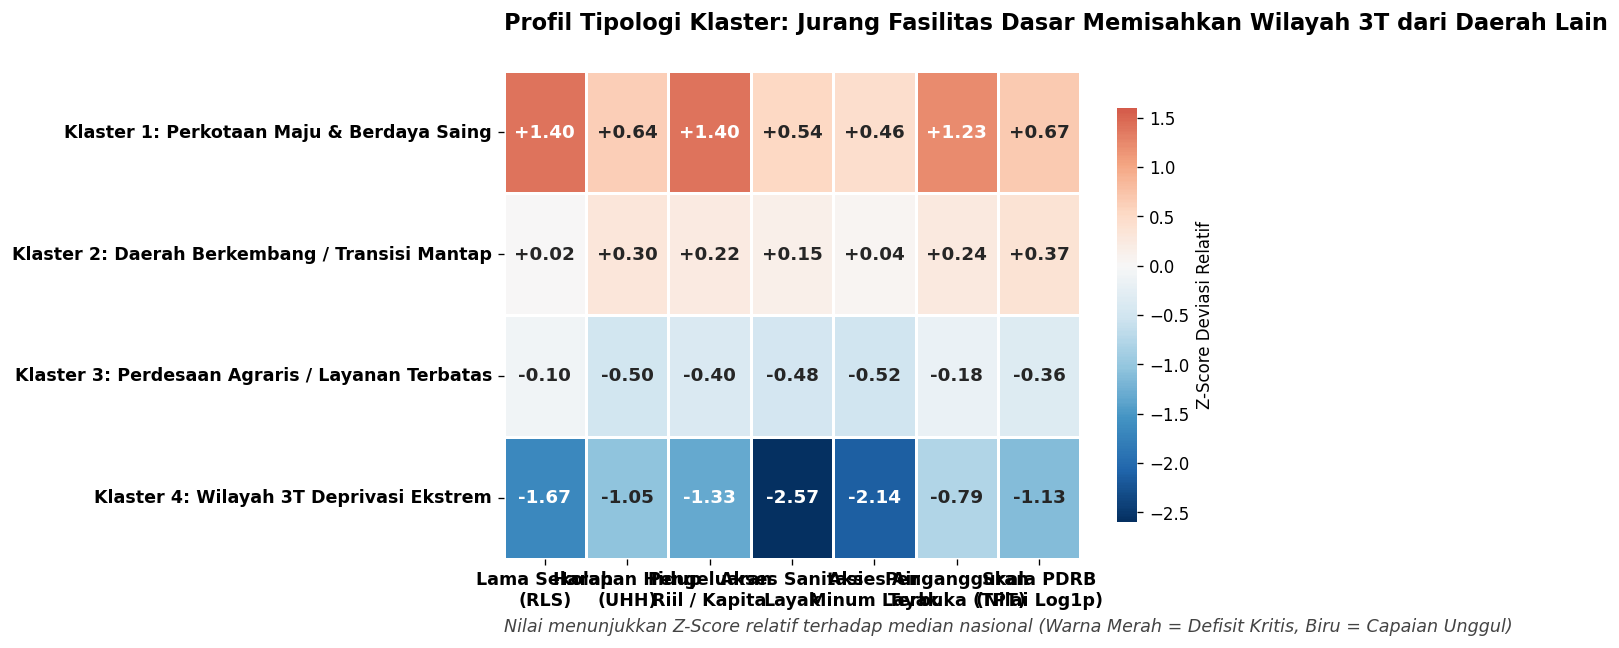

Gambar 4 berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\04_cluster_characteristics_heatmap.png


In [6]:
# Menghitung Z-Score Rata-rata per Klaster
z_df = pd.DataFrame(X_scaled, columns=FEATURE_COLS)
z_df['cluster_name'] = df['cluster_name']

ordered_names = [CLUSTER_LABELS[i] for i in range(4)]
z_summary = z_df.groupby('cluster_name').mean().reindex(ordered_names)

# Label sumbu X dibuat 2 baris bersih, proporsional, dan ringkas (Mencegah Tabrakan Teks)
z_summary_display = z_summary.rename(columns={
    'avg_school_years': 'Lama Sekolah\n(RLS)',
    'life_expectancy': 'Harapan Hidup\n(UHH)',
    'expenditure_per_capita': 'Pengeluaran\nRiil / Kapita',
    'sanitation_access_pct': 'Akses Sanitasi\nLayak',
    'clean_water_access_pct': 'Akses Air\nMinum Layak',
    'unemployment_rate_tpt': 'Pengangguran\nTerbuka (TPT)',
    'log_pdrb': 'Skala PDRB\n(Nilai Log1p)'
})

# Visualisasi Heatmap Matrix Lega & Bersih
fig, ax = plt.subplots(figsize=(12.5, 5.8), dpi=300)

sns.heatmap(
    z_summary_display,
    annot=True,
    fmt='+.2f',
    cmap='RdBu',       # Merah = Negatif/Defisit Kritis, Biru = Positif/Capaian Unggul
    center=0,
    vmin=-2.6,
    vmax=1.6,
    cbar=True,
    cbar_kws={'label': 'Z-Score Deviasi Relatif', 'shrink': 0.85},
    linewidths=1.5,
    linecolor='white',
    annot_kws={'size': 11, 'weight': 'bold'},
    ax=ax
)

# Judul Utama & Subjudul Proporsional dengan Jarak Cukup
ax.set_title('Profil Tipologi Klaster: Jurang Fasilitas Dasar Memisahkan Wilayah 3T dari Daerah Lain\n'
             'Nilai Z-Score relatif terhadap median nasional (Warna Merah = Defisit Kritis, Biru = Capaian Unggul)',
             fontsize=12.5, fontweight='bold', pad=18, loc='left')

ax.set_ylabel('')

# Sumbu X Diformat Rapi & Tegas (0 Derajat, Center)
plt.xticks(rotation=0, fontsize=10.5, fontweight='bold', ha='center')
plt.yticks(fontsize=10.5, fontweight='bold')

# Simpan resolusi 300 DPI untuk PPT
fig4_path = FIG_DIR / '04_cluster_characteristics_heatmap.png'
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gambar 4 berhasil disimpan ke: {fig4_path.resolve()}")

---
## 7. Visual 5 (Slide Evaluasi): Sebaran Kemiskinan Aktual ($P_0$) per Klaster

* **Tujuan Slide PPT:** Menyajikan bukti validasi eksternal bahwa pemodelan klaster berhasil membedakan tingkat kemiskinan secara berjenjang, meskipun $P_0$ tidak digunakan dalam proses pelatihan.
* **Prinsip SWD:** Menggantikan boxplot dengan Jittered Strip Plot yang memperlihatkan titik rill 514 daerah dan garis penanda median yang diberi label langsung (*direct labeling*).

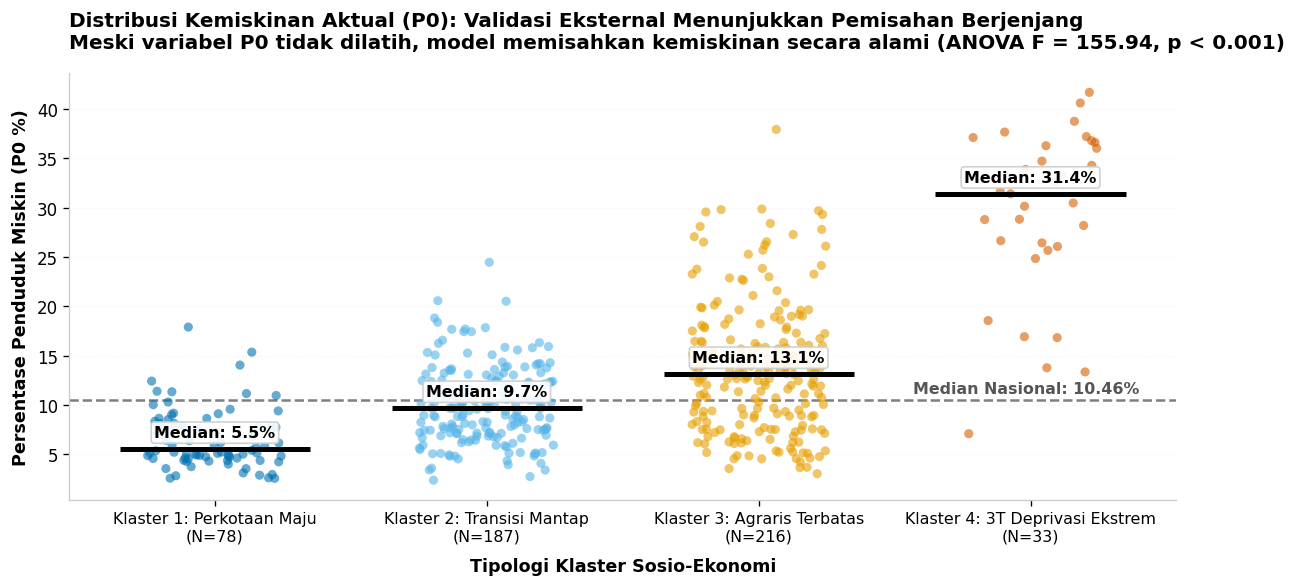

Gambar 5 berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\05_poverty_distribution_stripplot.png


In [7]:
# Visualisasi Jittered Strip Plot Bergaya SWD
fig, ax = plt.subplots(figsize=(10.5, 5.2), dpi=300)

sns.stripplot(
    data=df,
    x='cluster_id',
    y='poverty_rate_p0',
    palette=CLUSTER_PALETTE,
    hue='cluster_id',
    legend=False,
    size=5.5,
    jitter=0.25,
    alpha=0.6,
    edgecolor='none',
    ax=ax
)

# Garis penanda median rill tebal & Direct Labeling
medians = df.groupby('cluster_id')['poverty_rate_p0'].median()
for cid, med in medians.items():
    ax.hlines(y=med, xmin=cid - 0.35, xmax=cid + 0.35, color='black', linewidth=3, zorder=5)
    ax.text(cid, med + 1.2, f'Median: {med:.1f}%', ha='center', fontsize=9.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#CCCCCC', alpha=0.9))

# Garis referensi median nasional
median_national = df['poverty_rate_p0'].median()
ax.axhline(median_national, color='#7F7F7F', linestyle='--', linewidth=1.5, zorder=2)
ax.text(3.45, median_national + 0.8, f'Median Nasional: {median_national:.2f}%',
        color='#555555', fontsize=9.5, fontweight='bold', ha='right')

# Action Title
ax.set_title('Validasi Eksternal: Distribusi Kemiskinan Aktual (P0)\nKlaster memisahkan kemiskinan secara alami tanpa variabel P0 (ANOVA F = 155.9, p < 0.001)',
             fontsize=12, fontweight='bold', pad=15, loc='left')
ax.set_xlabel('Tipologi Klaster Sosio-Ekonomi', fontsize=10.5, fontweight='bold', labelpad=8)
ax.set_ylabel('Persentase Penduduk Miskin (P0 %)', fontsize=10.5, fontweight='bold')
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels([
    'Klaster 1 (N=78)\nPerkotaan Modern & Formal',
    'Klaster 2 (N=187)\nKabupaten Penyangga Mapan',
    'Klaster 3 (N=216)\nPerdesaan Agraris Rentan',
    'Klaster 4 (N=33)\n3T Deprivasi Akut'
], fontsize=9.5)
ax.grid(axis='y', linestyle=':', alpha=0.5)

# Simpan resolusi 300 DPI untuk PPT
fig5_path = FIG_DIR / '05_poverty_distribution_stripplot.png'
plt.savefig(fig5_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Gambar 5 berhasil disimpan ke: {fig5_path.resolve()}')

---
## 8. Visual 6 (Slide Evaluasi): Matriks Skrining Kerentanan Relatif 2x2

* **Tujuan Slide PPT:** Menampilkan instrumen operasional skrining kebijakan yang menyaring wilayah prioritas intervensi darurat (Kuadran I) vs daerah kantong kemiskinan (Kuadran III).
* **Prinsip SWD:** Memberikan kartu teks anotasi langsung pada 4 kuadran yang menjelaskan arah kebijakan operasional masing-masing kuadran.

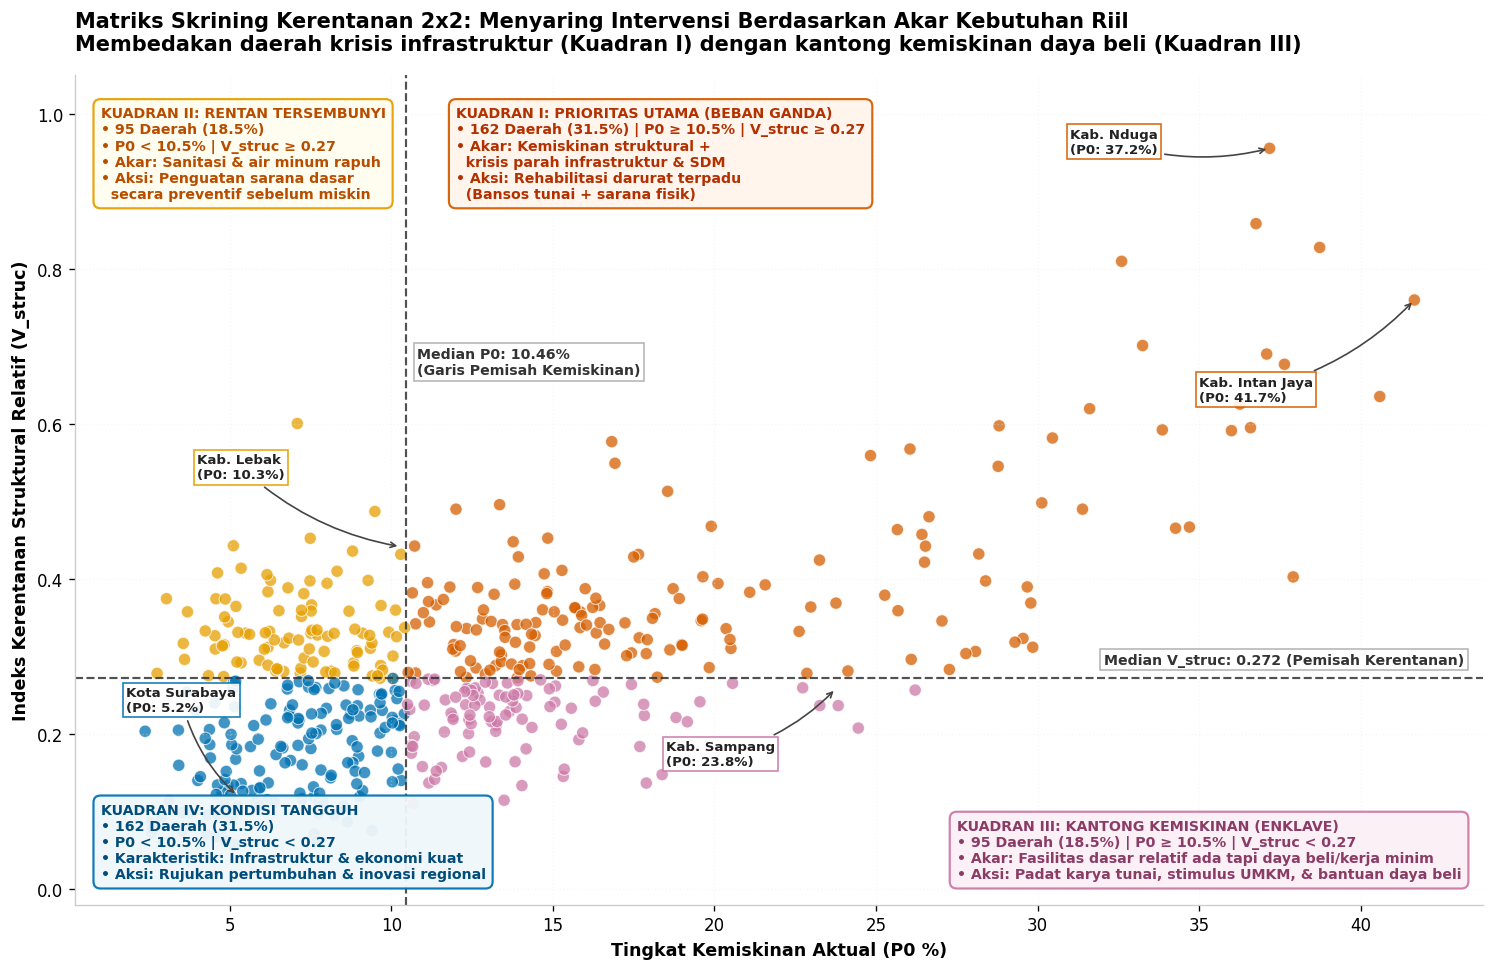

Gambar 6 berhasil disimpan ke: D:\ARFI\Kuliah\Project\project-semester5\PovertyRadar\reports\figures\06_relative_vulnerability_matrix_2x2.png


In [8]:
# Visualisasi Matriks Kuadran 2x2 Bergaya SWD (Direct Labeling, No Redundant Legend)
fig, ax = plt.subplots(figsize=(13, 8.2), dpi=300)

med_p0 = df['poverty_rate_p0'].median()
med_v  = df['vulnerability_score'].median()

quad_palette = {
    'Kuadran I (Prioritas Utama)': '#D55E00',             # Vermillion (Warning)
    'Kuadran II (Potensi Rentan Tersembunyi)': '#E69F00',  # Amber
    'Kuadran III (Kantong Kemiskinan / Enklave)': '#CC79A7', # Soft Rose/Purple
    'Kuadran IV (Kondisi Tangguh)': '#0072B2'             # Blue
}

# 1. Scatter Plot
sns.scatterplot(
    data=df,
    x='poverty_rate_p0',
    y='vulnerability_score',
    hue='vulnerability_quadrant',
    palette=quad_palette,
    alpha=0.75,
    s=55,
    edgecolor='white',
    linewidth=0.6,
    legend=False,
    ax=ax
)

# 2. Garis Ambang Batas Kartesius (Median Nasional)
ax.axvline(med_p0, color='#333333', linestyle='--', linewidth=1.3, alpha=0.85)
ax.axhline(med_v, color='#333333', linestyle='--', linewidth=1.3, alpha=0.85)

# Label teks pada garis median
ax.text(med_p0 + 0.35, 0.68, f'Median P0: {med_p0:.2f}%\n(Garis Pemisah Kemiskinan)', 
        fontsize=8.5, color='#333333', fontweight='bold', va='center',
        bbox=dict(boxstyle='square,pad=0.25', facecolor='white', edgecolor='#B0B0B0', alpha=0.9))

ax.text(43.2, med_v + 0.015, f'Median V_struc: {med_v:.3f} (Pemisah Kerentanan)', 
        fontsize=8.5, color='#333333', fontweight='bold', ha='right', va='bottom',
        bbox=dict(boxstyle='square,pad=0.25', facecolor='white', edgecolor='#B0B0B0', alpha=0.9))

# 3. Label Kotak Kuadran & Aksi Kebijakan
box_q1 = dict(boxstyle='round,pad=0.5', facecolor='#FFF5EB', edgecolor='#D55E00', linewidth=1.3, alpha=0.95)
box_q2 = dict(boxstyle='round,pad=0.5', facecolor='#FFFDF0', edgecolor='#E69F00', linewidth=1.3, alpha=0.95)
box_q3 = dict(boxstyle='round,pad=0.5', facecolor='#FAF0F5', edgecolor='#CC79A7', linewidth=1.3, alpha=0.95)
box_q4 = dict(boxstyle='round,pad=0.5', facecolor='#F0F7FA', edgecolor='#0072B2', linewidth=1.3, alpha=0.95)

# Kuadran II: Top-Left
ax.text(1.0, 1.01, 
        'KUADRAN II: RENTAN TERSEMBUNYI\n'
        '• 95 Daerah (18.5%) | P0 < 10.5% | V_struc ≥ 0.27\n'
        '• Akar: Sanitasi & air minum rapuh\n'
        '• Aksi: Penguatan sarana dasar preventif\n'
        '  guna mencegah kerentanan jatuh miskin',
        fontsize=8.5, fontweight='bold', color='#B84D00', bbox=box_q2, va='top')

# Kuadran I: Top-Center
ax.text(12.0, 1.01, 
        'KUADRAN I: PRIORITAS UTAMA (BEBAN GANDA)\n'
        '• 162 Daerah (31.5%) | P0 ≥ 10.5% | V_struc ≥ 0.27\n'
        '• Akar: Kemiskinan struktural +\n'
        '  krisis parah infrastruktur & SDM\n'
        '• Aksi: Rehabilitasi darurat terpadu\n'
        '  (Bansos tunai + sarana fisik)',
        fontsize=8.5, fontweight='bold', color='#B33000', bbox=box_q1, va='top')

# Kuadran IV: Bottom-Left
ax.text(1.0, 0.01, 
        'KUADRAN IV: KONDISI TANGGUH\n'
        '• 162 Daerah (31.5%) | P0 < 10.5% | V_struc < 0.27\n'
        '• Karakteristik: Infrastruktur & ekonomi kuat\n'
        '• Aksi: Rujukan pertumbuhan & inovasi regional',
        fontsize=8.5, fontweight='bold', color='#004C7A', bbox=box_q4, va='bottom')

# Kuadran III: Bottom-Right
ax.text(27.0, 0.01, 
        'KUADRAN III: KANTONG KEMISKINAN (ENKLAVE)\n'
        '• 95 Daerah (18.5%) | P0 ≥ 10.5% | V_struc < 0.27\n'
        '• Akar: Sarana dasar memadai, namun daya beli & kerja terbatas\n'
        '• Aksi: Padat karya tunai, stimulus UMKM, & bantuan daya beli',
        fontsize=8.5, fontweight='bold', color='#8A3B66', bbox=box_q3, va='bottom')

# 4. Anotasi Benchmark Kabupaten/Kota Kunci (Contextual Anchors)
benchmark_points = [
    ('Kab. Nduga', 37.18, 0.9557, (31.0, 0.95), '#D55E00'),
    ('Kab. Intan Jaya', 41.66, 0.7600, (35.0, 0.63), '#D55E00'),
    ('Kab. Sampang', 23.76, 0.2589, (18.5, 0.16), '#CC79A7'),
    ('Kota Surabaya', 5.23, 0.1205, (1.8, 0.23), '#0072B2'),
    ('Kab. Lebak', 10.29, 0.4418, (4.0, 0.53), '#E69F00'),
]

for name, px, py, (tx, ty), col in benchmark_points:
    ax.annotate(
        f'{name}\n(P0: {px:.1f}%)',
        xy=(px, py),
        xytext=(tx, ty),
        fontsize=8,
        fontweight='bold',
        color='#222222',
        bbox=dict(boxstyle='square,pad=0.25', facecolor='white', edgecolor=col, alpha=0.9),
        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.15', color='#444444', lw=1.0)
    )

# 5. Styling & Despining
ax.set_title('Matriks Skrining Kerentanan 2x2: Menyaring Intervensi Berdasarkan Akar Kebutuhan Riil\n'
             'Diferensiasi intervensi darurat (Kuadran I), perlindungan preventif (Kuadran II), dan stimulus ekonomi (Kuadran III)',
             fontsize=12.5, fontweight='bold', pad=15, loc='left')
ax.set_xlabel('Tingkat Kemiskinan Aktual (P0 %)', fontsize=10.5, fontweight='bold')
ax.set_ylabel('Indeks Kerentanan Struktural Relatif (V_struc)', fontsize=10.5, fontweight='bold')

ax.set_xlim(0.2, 43.8)
ax.set_ylim(-0.02, 1.05)

ax.grid(True, linestyle=':', alpha=0.35)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Simpan resolusi 300 DPI untuk PPT
fig6_path = FIG_DIR / '06_relative_vulnerability_matrix_2x2.png'
plt.savefig(fig6_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gambar 6 berhasil disimpan ke: {fig6_path.resolve()}")

---
## 9. Ringkasan Aset Visual untuk Presentasi PowerPoint

Seluruh 6 gambar grafik telah berhasil dibuat dan disimpan di folder `reports/figures/`:

| Nama Berkas Gambar | Penempatan Slide PPT | Pesan Inti (Action Headline) |
| :--- | :---: | :--- |
| `01_model_evaluation_elbow_silhouette.png` | **Slide 4: Metode** | **"Titik Belok k = 4 Menghasilkan Kompromi Optimal"** (Inersia melandai tegas). |
| `02_multiseed_robustness_ari.png` | **Slide 5: Evaluasi** | **"Stabilitas Konsistensi 98.7% di 20 Random Seed"** (Bukan kebetulan acak). |
| `03_pca_cluster_projection_2d.png` | **Slide 5: Evaluasi** | **"Dua Dimensi Utama Memisahkan 4 Klaster Secara Tegas"** (Manusia vs Ekonomi). |
| `04_cluster_characteristics_heatmap.png` | **Slide 5: Evaluasi** | **"Jurang Fasilitas Dasar Memisahkan Daerah 3T"** (Substitusi Radar Chart). |
| `05_poverty_distribution_stripplot.png` | **Slide 5: Evaluasi** | **"Validasi Eksternal: Pemisahan Kemiskinan Berjenjang Sempurna"** (ANOVA p < 0.001). |
| `06_relative_vulnerability_matrix_2x2.png` | **Slide 5: Evaluasi** | **"Skrining 2x2: Menyaring 162 Wilayah Prioritas Beban Ganda"** (Arah Kebijakan). |